<a href="https://colab.research.google.com/github/Fespinoza1477/walmart-hurricane-project/blob/main/notebooks/06-midterm-walmart/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [ ]:
# TODO: the numbers
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Load the team's transaction data
DATA_URL = (
    "https://raw.githubusercontent.com/Fespinoza1477/"
    "walmart-hurricane-project/main/Data/walmart_transactions.csv"
)
trans_raw = pd.read_csv(DATA_URL)
trans = trans_raw.drop_duplicates(
    subset="transaction_id", keep="first"
).reset_index(drop=True)

# Canonical SKU mapping from our team notebook
sku_map = {
    "PT-12": "POPTART-STRAW", "SKU#459812": "POPTART-STRAW",
    "POPTART-STRAW": "POPTART-STRAW", "PT_STRAWBERRY": "POPTART-STRAW",
    "WTR-24": "WATER24PK", "WATER24PK": "WATER24PK", "WTR_24PK": "WATER24PK",
    "BATT-100": "BAT-AA4", "BAT-AA4": "BAT-AA4", "BATT_AA_4PK": "BAT-AA4",
    "FLASH-01": "LED-FLASH", "LED-FLASH": "LED-FLASH",
    "BEER-24": "BEER-24", "LTBEER24": "BEER-24",
    "BG-MONO": "GAME-MONO", "MONOPOLY-01": "GAME-MONO", "GAME-MONO": "GAME-MONO",
    "CARDS-01": "CARDS-01", "PLAYCARD-STD": "CARDS-01",
    "STREAM-01": "STREAM-01", "ROKU-STD": "STREAM-01",
    "SOUP-CAN": "SOUP", "CNSOUP-01": "SOUP",
    "BREAD-WH": "WHITEBREAD", "WHITEBREAD": "WHITEBREAD",
    "PB-16": "PNUTBTR", "PNUTBTR-16": "PNUTBTR",
    "CNDL-EM": "EMERG-CNDL", "CANDLE-EMRG": "EMERG-CNDL",
    "FAID-01": "FIRSTAID-KIT", "FIRSTAID-KIT": "FIRSTAID-KIT",
    "CHRG-PORT": "CHRGR", "PORTCHARGER": "CHRGR",
    "CHIPS-VP": "CHIPS-VP", "CHIPVARIETY": "CHIPS-VP",
    "PTOWEL-6": "PTOWEL", "PAPERTOWEL6": "PTOWEL",
    "TP-12": "TOILETPAPER", "TOILETPAPER12": "TOILETPAPER",
    "DIAP-S3": "DIAPERS", "DIAPERS-3": "DIAPERS",
    "BFORM-01": "BABYFORM", "BABYFORMULA": "BABYFORM",
    "TARP-HD": "TARP-HD", "HDTARP-01": "TARP-HD",
}
sku_map = {k.upper(): v.upper() for k, v in sku_map.items()}

trans["sku_original"] = trans["sku"].astype(str).str.strip().str.upper()
trans["sku"] = trans["sku_original"].replace(sku_map)

category_map = {
    "Breakfast Foods": "Breakfast",
    "Emergency Supplies": "Emergency",
    "Alcoholic Beverages": "Alcohol",
    "Groceries": "Grocery",
    "Baby": "Baby Products",
    "Games & Entertainment": "Entertainment",
    "Household Essentials": "Household",
    "Health & Wellness": "Health",
}
trans["category"] = (
    trans["category"].astype(str).str.strip().str.lower().str.title()
    .replace(category_map)
)

# Parse the timestamp formats used in the source data
ts = trans["timestamp"].astype("string").str.strip().replace(
    {"": pd.NA, "NULL": pd.NA, "N/A": pd.NA, "NaN": pd.NA, "nan": pd.NA}
)
parsed = pd.Series(pd.NaT, index=trans.index)
for fmt in [
    "%Y-%m-%d %H:%M:%S",
    "%Y-%m-%dT%H:%M:%S",
    "%m/%d/%Y %H:%M",
    "%d-%b-%Y %H:%M",
    "%m-%d-%Y %H:%M:%S",
]:
    mask = parsed.isna() & ts.notna()
    parsed.loc[mask] = pd.to_datetime(ts.loc[mask], format=fmt, errors="coerce")

trans["timestamp"] = parsed
trans["date"] = pd.to_datetime(trans["timestamp"].dt.date)
trans["quantity"] = pd.to_numeric(trans["quantity"], errors="coerce")
analysis_trans = trans.dropna(subset=["date", "quantity"]).copy()

# Daily totals for September 2024
date_range = pd.date_range("2024-09-01", "2024-09-30")
daily_units = (
    analysis_trans.groupby("date")["quantity"].sum()
    .reindex(date_range, fill_value=0)
)

baseline = daily_units.loc["2024-09-08":"2024-09-15"]
surge = daily_units.loc["2024-09-23":"2024-09-25"]
baseline_mean = baseline.mean()
surge_mean = surge.mean()
q1_multiple = surge_mean / baseline_mean

print(f"Baseline (Sept 8–15): {baseline_mean:.2f} units/day, n={len(baseline)} days")
print(f"Surge (Sept 23–25): {surge_mean:.2f} units/day, n={len(surge)} days")
print(f"Surge multiple: {q1_multiple:.2f}x")

# Category details from the same windows
daily_category = (
    analysis_trans.groupby(["date", "category"])["quantity"].sum()
    .unstack("category")
    .reindex(date_range, fill_value=0)
)
top5 = daily_category.sum().nlargest(5).index
category_results = pd.DataFrame({
    "baseline_units_per_day": daily_category.loc["2024-09-08":"2024-09-15", top5].mean(),
    "surge_units_per_day": daily_category.loc["2024-09-23":"2024-09-25", top5].mean(),
})
category_results["multiple"] = (
    category_results["surge_units_per_day"] /
    category_results["baseline_units_per_day"]
)
display(category_results.round(2))

Baseline (Sept 8–15): 1091.25 units/day, n=8 days
Surge (Sept 23–25): 3504.00 units/day, n=3 days
Surge multiple: 3.21x


,baseline_units_per_day,surge_units_per_day,multiple
category,,,
Emergency,350.62,1335.67,3.81
Grocery,169.25,364.67,2.15
Breakfast,72.75,524.33,7.21
Entertainment,101.88,302.00,2.96
Household,83.75,220.00,2.63


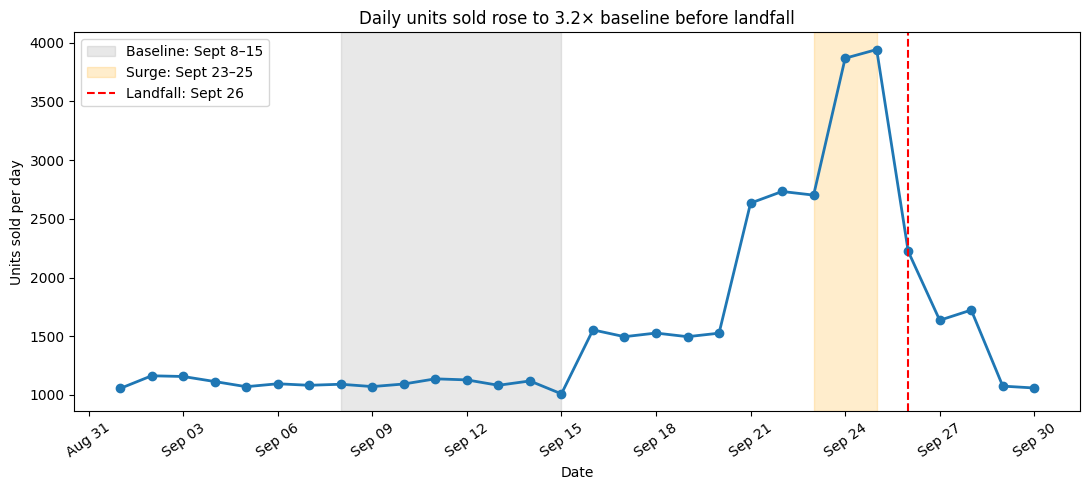

In [ ]:
# TODO: the chart
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily_units.index, daily_units.values, marker="o", linewidth=2)
ax.axvspan(pd.Timestamp("2024-09-08"), pd.Timestamp("2024-09-15"),
           color="gray", alpha=0.18, label="Baseline: Sept 8–15")
ax.axvspan(pd.Timestamp("2024-09-23"), pd.Timestamp("2024-09-25"),
           color="orange", alpha=0.2, label="Surge: Sept 23–25")
ax.axvline(pd.Timestamp("2024-09-26"), color="red", linestyle="--",
           label="Landfall: Sept 26")
ax.set_title(f"Daily units sold rose to {q1_multiple:.1f}× baseline before landfall")
ax.set_xlabel("Date")
ax.set_ylabel("Units sold per day")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend()
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:**
From September 8–15, the team averaged 1,091.25 units per day; during September 23–25, the average rose to 3,504 units per day, or 3.21× baseline, before September 26 landfall.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

,Measure,Before consolidation,After consolidation
0,Distinct SKUs,45,20
1,Total units in deduplicated transactions,49343,49343


Largest family: Pop-Tarts Strawberry — 4 original SKU variants map to POPTART-STRAW
Unit-total assertion passed: 49,343 units before and after.


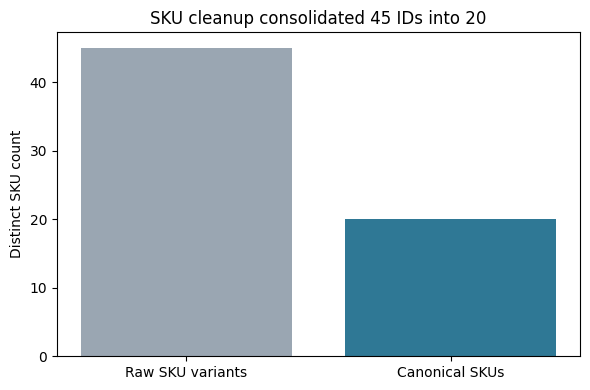

In [ ]:
# Compare raw SKU variants with canonical SKUs after transaction-ID deduplication
units_before = trans["quantity"].sum()
units_after = trans.groupby("sku")["quantity"].sum().sum()
assert np.isclose(units_before, units_after), "SKU consolidation changed unit totals"

sku_counts = (
    trans.groupby("sku")
    .agg(original_sku_count=("sku_original", "nunique"),
         units=("quantity", "sum"))
    .sort_values("original_sku_count", ascending=False)
)

before_skus = trans["sku_original"].nunique()
after_skus = trans["sku"].nunique()
largest_sku = sku_counts["original_sku_count"].idxmax()
largest_count = int(sku_counts.loc[largest_sku, "original_sku_count"])
largest_name = {
    "POPTART-STRAW": "Pop-Tarts Strawberry",
    "BAT-AA4": "AA Batteries 4-Pack",
    "GAME-MONO": "Monopoly Board Game",
    "WATER24PK": "Bottled Water 24-Pack",
}.get(largest_sku, largest_sku)

comparison = pd.DataFrame({
    "Measure": ["Distinct SKUs", "Total units in deduplicated transactions"],
    "Before consolidation": [before_skus, units_before],
    "After consolidation": [after_skus, units_after],
})
display(comparison)
print(f"Largest family: {largest_name} — {largest_count} original SKU variants "
      f"map to {largest_sku}")
print(f"Unit-total assertion passed: {units_before:,.0f} units before and after.")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Raw SKU variants", "Canonical SKUs"], [before_skus, after_skus],
       color=["#9aa6b2", "#2f7895"])
ax.set_title(f"SKU cleanup consolidated {before_skus} IDs into {after_skus}")
ax.set_ylabel("Distinct SKU count")
plt.tight_layout()
plt.show()

**Q2 answer:** We consolidated 45 distinct raw SKUs into 20 canonical SKUs/products; the largest family was Pop-Tarts Strawberry, with four raw SKU variants mapped to one canonical SKU, and the assertion confirms that consolidation preserved the deduplicated transaction unit total.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Weather source: Open-Meteo live
Rows before join: 30
Rows after join: 30
Matched rows: 30
Days in correlation: 30
Same-day sales vs. wind: r=0.40
Same-day sales vs. precipitation: r=-0.26
Highest lagged sales/wind correlation: 0.82 (wind 2 days later)


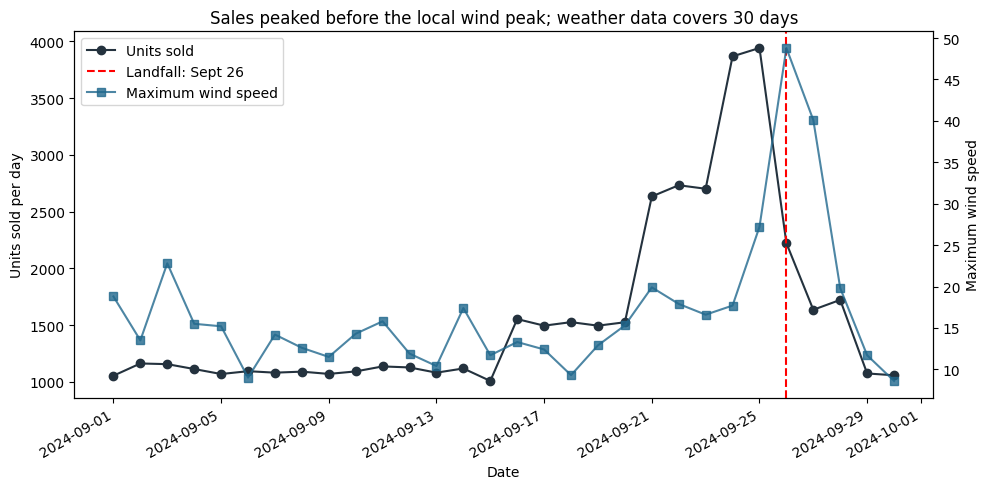

In [ ]:
 # Retry the weather request for temporary network/server errors
session = requests.Session()
retry = Retry(
    total=4, backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)
session.mount("https://", HTTPAdapter(max_retries=retry))

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 28.54, "longitude": -81.38,  # Orlando proxy used in the repo
    "start_date": "2024-09-01", "end_date": "2024-09-30",
    "daily": ["precipitation_sum", "wind_speed_10m_max"],
    "timezone": "America/New_York",
}
response = session.get(url, params=params, timeout=20)
response.raise_for_status()

weather = pd.DataFrame(response.json()["daily"]).rename(columns={"time": "date"})
weather["date"] = pd.to_datetime(weather["date"])
weather["source"] = "Open-Meteo live"

daily_sales = (
    analysis_trans.groupby("date", as_index=False)["quantity"].sum()
    .rename(columns={"quantity": "units_sold"})
)
joined = daily_sales.merge(
    weather, on="date", how="left", validate="one_to_one", indicator=True
)

print("Weather source:", weather["source"].iloc[0])
print("Rows before join:", len(daily_sales))
print("Rows after join:", len(joined))
print("Matched rows:", int((joined["_merge"] == "both").sum()))
assert len(joined) == len(daily_sales), "Join changed the sales row count"
assert joined["_merge"].eq("both").all(), "Some sales dates have no weather match"
assert np.isclose(joined["units_sold"].sum(), daily_sales["units_sold"].sum())
joined = joined.drop(columns="_merge")

same_day_wind_r = joined["units_sold"].corr(joined["wind_speed_10m_max"])
same_day_rain_r = joined["units_sold"].corr(joined["precipitation_sum"])
lag_corrs = {
    k: joined["units_sold"].corr(joined["wind_speed_10m_max"].shift(-k))
    for k in range(6)
}
best_lag = max(lag_corrs, key=lag_corrs.get)

print(f"Days in correlation: {len(joined)}")
print(f"Same-day sales vs. wind: r={same_day_wind_r:.2f}")
print(f"Same-day sales vs. precipitation: r={same_day_rain_r:.2f}")
print(f"Highest lagged sales/wind correlation: {lag_corrs[best_lag]:.2f} "
      f"(wind {best_lag} days later)")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(joined["date"], joined["units_sold"], marker="o",
        color="#24323E", label="Units sold")
ax.set_ylabel("Units sold per day")
ax.set_xlabel("Date")
ax.axvline(pd.Timestamp("2024-09-26"), color="red", linestyle="--",
           label="Landfall: Sept 26")
ax2 = ax.twinx()
ax2.plot(joined["date"], joined["wind_speed_10m_max"], color="#21688D",
         marker="s", alpha=0.8, label="Maximum wind speed")
ax2.set_ylabel("Maximum wind speed")
ax.set_title("Sales peaked before the local wind peak; weather data covers 30 days")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** The left join preserved all 30 of 30 sales days and used live Open-Meteo data for an Orlando-area weather proxy; sales were moderately correlated with same-day maximum wind (r ≈ 0.40) and most strongly with wind two days later (r ≈ 0.82), but the 30-day sample and single weather location limit how broadly we can interpret that relationship.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** A store-level wind comparison and regional sales chart are drafted. Sam is finishing the location checks, including the store with missing coordinates and inconsistent region labels.

**Q5 (signal or artifact):** Inventory comparisons are drafted, but Fabi still needs to resolve the transaction/database mismatch before treating inventory as independent confirmation of the surge.

### Self-check

In [ ]:
progress = {
    'q1_multiple': 3.2,            # TODO: a number
    'q1_baseline_window': '2024-09-08 to 2024-09-15',   # TODO: stated explicitly
    'q2_canonical_products': 20,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': 3,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 3.2
PASS - q1_baseline_window = 2024-09-08 to 2024-09-15
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a)** We were surprised that daily units sold averaged about 3.2 times the baseline in the three days before landfall. We checked the transaction-ID removal of duplicates and confirmed the baseline and surge windows each contain all their expected dates. We used a longer baseline that includes the early climb lowers the multiple, so the result depends on the stated window.

**b)** We are least confident in the inventory cross-check: most matched store/date/category rows do not agree between the transaction data and the sales database. Until we explain that mismatch, we would not use inventory records as proof that the demand surge is genuine.